In [12]:
from langgraph.graph import StateGraph,START,END
from langchain_mistralai import ChatMistralAI
from dotenv import load_dotenv
from typing import TypedDict
from pydantic import BaseModel,Field
from rich import print

In [4]:
load_dotenv()

True

In [5]:
# model
llm = ChatMistralAI(model='ministral-3b-2512')

In [6]:
class EvaluationEssay(BaseModel):

    feedback: str = Field(description='Detailed feedback for essay')
    score: int = Field(description='Score out of 10', ge=0, le=10)

In [7]:
structured_llm = llm.with_structured_output(EvaluationEssay)

In [9]:
essay = """Road safety in India is a critical public health and economic challenge. Despite boasting one of the world's largest road networks, India tragically ranks among the highest globally in traffic-related fatalities. According to data from the Ministry of Road Transport and Highways (MoRTH), over 1.5 lakh people lose their lives annually in road accidents, translating to a devastating loss of human potential and billions of rupees in economic damage.The crisis stems from a combination of human error, structural flaws, and weak enforcement. Over-speeding, distracted driving, and driving under the influence are the primary catalysts for fatal crashes. Furthermore, a widespread reluctance to wear helmets or seatbelts drastically escalates injury severity. This human factor is exacerbated by infrastructural gaps, such as poorly engineered blind spots, potholes, and a lack of dedicated lanes for pedestrians and cyclists.To combat this, the Indian government enacted the Motor Vehicles (Amendment) Act, which imposed stricter penalties for traffic violations and introduced electronic enforcement through speed cameras and e-challans. Programs to systematically fix high-accident "black spots" on national highways are also underway.However, legislation alone cannot fix the problem; a cultural shift is required. Road safety must be approached through the "4 Es": Engineering, Enforcement, Education, and Emergency Care. Educating the youth on traffic discipline and expanding medical infrastructure to utilize the "Golden Hour"—the critical first hour after a crash—are vital steps to saving lives.Ultimately, road safety is a shared responsibility. While the government must ensure well-designed roads and strict law enforcement, citizens must cultivate patience, obey traffic rules, and practice defensive driving. Only through this collective commitment can India transform its transport network into a safe corridor for national progress."""

In [10]:
prompt = f"Evalute the language quelity of following essay and provide the feedback and assign a score of out 10 \n {essay} "

In [11]:
responce = structured_llm.invoke(prompt)

In [13]:
print(responce)

EvaluationEssay(
    feedback="1. **Clarity and Coherence**: The essay is well-structured and coherent, making it easy to follow. 
Each paragraph logically progresses to address different aspects of the topic, from the problem to potential 
solutions. The flow is smooth, and the ideas are presented in a sequential manner.\n\n2. **Grammar and Syntax**: 
The language is grammatically correct and syntactically sound. There are no major grammatical errors, and the use 
of complex sentences effectively supports the arguments. Minor improvements could include varying sentence 
structures to enhance readability.\n\n3. **Vocabulary and Precision**: The vocabulary is rich and appropriate for 
the topic. Words like 'devastating,' 'escalates,' 'infrastructural,' and 'collective' effectively convey the 
gravity of the issue and the proposed solutions. However, occasional repetition (e.g., 'problem' and 'crisis' used 
interchangeably) could be varied for better fluency.\n\n4. **Depth of Analysis**: The essay provides a thorough 
analysis of the road safety crisis in India, covering human factors, infrastructural gaps, and government 
initiatives. The discussion of the '4 Es' (Engineering, Enforcement, Education, Emergency Care) is insightful and 
offers a comprehensive approach to the problem.\n\n5. **Persuasiveness and Call to Action**: The conclusion 
effectively emphasizes the shared responsibility of the government and citizens, reinforcing the importance of a 
cultural shift. The use of phrases like 'collective commitment' and 'safe corridor' adds persuasiveness to the 
argument.\n\n6. **Data Integration**: The inclusion of statistical data (e.g., 1.5 lakh fatalities annually) 
strengthens the argument by providing concrete evidence of the issue's severity. However, citing sources like the 
Ministry of Road Transport and Highways could enhance credibility further.\n\n7. **Suggestions for Improvement**: 
\n   - Vary sentence structures to prevent monotony and improve readability.\n   - Consider using transitions 
between paragraphs to explicitly connect ideas (e.g., 'Moreover,' 'Additionally,' 'In conclusion').\n   - Expand 
slightly on the cultural shift by providing examples of how education and awareness campaigns could be 
implemented.\n\nOverall, the essay is well-written, informative, and persuasive. With minor refinements in 
vocabulary variation and transitions, it could achieve near-perfect clarity and impact.",
    score=9
)

In [14]:
print(responce.feedback)

1. **Clarity and Coherence**: The essay is well-structured and coherent, making it easy to follow. Each paragraph 
logically progresses to address different aspects of the topic, from the problem to potential solutions. The flow 
is smooth, and the ideas are presented in a sequential manner.

2. **Grammar and Syntax**: The language is grammatically correct and syntactically sound. There are no major 
grammatical errors, and the use of complex sentences effectively supports the arguments. Minor improvements could 
include varying sentence structures to enhance readability.

3. **Vocabulary and Precision**: The vocabulary is rich and appropriate for the topic. Words like 'devastating,' 
'escalates,' 'infrastructural,' and 'collective' effectively convey the gravity of the issue and the proposed 
solutions. However, occasional repetition (e.g., 'problem' and 'crisis' used interchangeably) could be varied for 
better fluency.

4. **Depth of Analysis**: The essay provides a thorough analysis of the road safety crisis in India, covering human
factors, infrastructural gaps, and government initiatives. The discussion of the '4 Es' (Engineering, Enforcement, 
Education, Emergency Care) is insightful and offers a comprehensive approach to the problem.

5. **Persuasiveness and Call to Action**: The conclusion effectively emphasizes the shared responsibility of the 
government and citizens, reinforcing the importance of a cultural shift. The use of phrases like 'collective 
commitment' and 'safe corridor' adds persuasiveness to the argument.

6. **Data Integration**: The inclusion of statistical data (e.g., 1.5 lakh fatalities annually) strengthens the 
argument by providing concrete evidence of the issue's severity. However, citing sources like the Ministry of Road 
Transport and Highways could enhance credibility further.

7. **Suggestions for Improvement**: 
   - Vary sentence structures to prevent monotony and improve readability.
   - Consider using transitions between paragraphs to explicitly connect ideas (e.g., 'Moreover,' 'Additionally,' 
'In conclusion').
   - Expand slightly on the cultural shift by providing examples of how education and awareness campaigns could be 
implemented.

Overall, the essay is well-written, informative, and persuasive. With minor refinements in vocabulary variation and
transitions, it could achieve near-perfect clarity and impact.

In [15]:
print(responce.score)

9

In [16]:
from typing import Annotated
import operator

In [30]:
class UPSCState(TypedDict):
    essay:str
    language_feedback:str
    analysis_feedback:str
    clarity_feedback:str
    overall_feedback:str
    individual_scores: Annotated[list[int],operator.add]
    avg_score:float

In [31]:
def evaluate_language(state: UPSCState):
    prompt = f"Evalute the language quelity of following essay and provide the feedback and assign a score of out 10 \n {state['essay']}"

    output =  structured_llm.invoke(prompt)

    return {'language_feedback':output.feedback,'individual_scores': [output.score]}

In [32]:
def evaluate_analysis(state:UPSCState):
    prompt = f"Evalute the depth of analysis following essay and provide the feedback and assign a score of out 10 \n {state['essay']}"
    
    output =  structured_llm.invoke(prompt)
    
    return {'analysis_feedback':output.feedback,'individual_scores': [output.score]}


In [33]:
def evaluate_thought(state:UPSCState):
    prompt = f"Evalute the clarity of thought following essay and provide the feedback and assign a score of out 10 \n {state['essay']}"
    
    output =  structured_llm.invoke(prompt)
    
    return {'clarity_feedback':output.feedback,'individual_scores': [output.score]}


In [34]:
def final_evalution(state:UPSCState):

    # generate the summary
    prompt = f"Based on the following feedbacks create a summarized feedback \n language_feedback - {state['language_feedback']} \n analysis_feedback - {state['analysis_feedback']} \n clarity_feedback - {state['clarity_feedback']} "

    overall_feedback = llm.invoke(prompt).content

    # avg calculte

    avg_sccore = 1.0*sum(state['individual_scores']) / len(state['individual_scores'])

    return {'overall_feedback':overall_feedback, 'avg_score':avg_sccore}

In [35]:
graph = StateGraph(UPSCState)

# nodes
graph.add_node('evaluate_language',evaluate_language)
graph.add_node('evaluate_analysis',evaluate_analysis)
graph.add_node('evaluate_thought',evaluate_thought)
graph.add_node('final_evalution',final_evalution)

# edges

graph.add_edge(START,'evaluate_language')
graph.add_edge(START,'evaluate_analysis')
graph.add_edge(START,'evaluate_thought')


graph.add_edge('evaluate_language','final_evalution')
graph.add_edge('evaluate_analysis','final_evalution')
graph.add_edge('evaluate_thought','final_evalution')

graph.add_edge('final_evalution',END)

workflow = graph.compile()


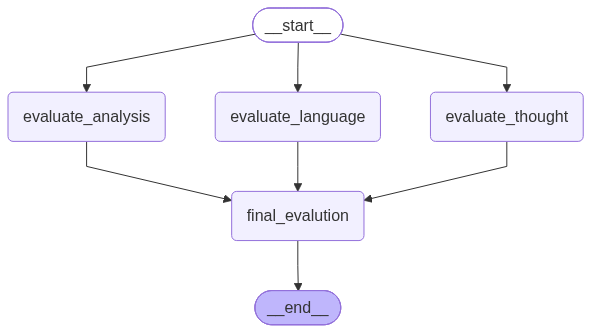

In [36]:
workflow

In [ ]:
initial_state = {
    'essay':essay,
}
final_state = workflow.invoke(initial_state)

In [41]:
final_state

{'essay': 'Road safety in India is a critical public health and economic challenge. Despite boasting one of the world\'s largest road networks, India tragically ranks among the highest globally in traffic-related fatalities. According to data from the Ministry of Road Transport and Highways (MoRTH), over 1.5 lakh people lose their lives annually in road accidents, translating to a devastating loss of human potential and billions of rupees in economic damage.The crisis stems from a combination of human error, structural flaws, and weak enforcement. Over-speeding, distracted driving, and driving under the influence are the primary catalysts for fatal crashes. Furthermore, a widespread reluctance to wear helmets or seatbelts drastically escalates injury severity. This human factor is exacerbated by infrastructural gaps, such as poorly engineered blind spots, potholes, and a lack of dedicated lanes for pedestrians and cyclists.To combat this, the Indian government enacted the Motor Vehicle

In [47]:
essay3 = """
AI in India: The Future or Big Problem?
Ajj kal, Artificial Intelligence (AI) is growing like anything in India, but honestly, some things are going very wrong. Everyone is hyping it up, saying AI will change tech, farming, and schools. But if we look at reality, it is creating a huge mess because of bad planning and half-baked tools.First of all, the biggest issue is jobs deletion. India already has so much unemployment, and now these big companies are using AI bots to fire poor workers. Customer care jobs, coding, and basic data entry are vanishing. What will the youth do? Eat AI code? The government is not doing anything to stop this corporate greed.Second thing is language and bias disaster. Most AI models are made by Americans who don’t understand India. When we use AI in Hindi or Tamil, it gives totally bakwaas (rubbish) translations and wrong info. It completely fails to understand local context and culture. Also, deepfakes are spreading like wildfire on WhatsApp, ruining people's reputations, and there is zero security.Lastly, education is becoming a joke. Students are not using their brains anymore. They just copy-paste everything from ChatGPT for assignments. Teachers are clueless, and kids are becoming lazy couch potatoes who can't think for themselves.In conclusion, AI feature in India is currently more of a headache than a help. Until we get strict laws and proper systems, AI will just keep ruining jobs, spreading fake news, and making people dumb. We need real solutions, not just fancy tech buzzwords.

"""


In [48]:
initial_state = {
    'essay':essay3,
}
final_state2 = workflow.invoke(initial_state)

In [49]:
final_state2

{'essay': "\nAI in India: The Future or Big Problem?\nAjj kal, Artificial Intelligence (AI) is growing like anything in India, but honestly, some things are going very wrong. Everyone is hyping it up, saying AI will change tech, farming, and schools. But if we look at reality, it is creating a huge mess because of bad planning and half-baked tools.First of all, the biggest issue is jobs deletion. India already has so much unemployment, and now these big companies are using AI bots to fire poor workers. Customer care jobs, coding, and basic data entry are vanishing. What will the youth do? Eat AI code? The government is not doing anything to stop this corporate greed.Second thing is language and bias disaster. Most AI models are made by Americans who don’t understand India. When we use AI in Hindi or Tamil, it gives totally bakwaas (rubbish) translations and wrong info. It completely fails to understand local context and culture. Also, deepfakes are spreading like wildfire on WhatsApp, 

In [51]:
essay4 = """ 
AI in indai: a totly bigest disastarAI is come in india very fastly but it is a totly waste of time and creating big big tension for common peple. Evryone is shouting AI AI like mad peple but realy it is just a big scam by rich company to make money and kick poor peple out of job.frst main problem is job lossing very badly. indai have so much population and young boys and girls dont have jobs. Now this stipud AI bots are doing coding and calling work. So many peple are getting fired from office. Family is crying bcoz no money. If AI do all work then what normal human will eat? stones? This is totly unfair and bad.secndly AI is totaly dumb and giving fake news. it dont know local language like hindi or marathi properly and making rubbish mistaks. Yestarday my frend ask something to chat gpt and it give totaly wrong corect answer. Also bad boys are making deepfakes of girls and putting on internet. No safety is there and police also sleeping. Internet is full of lies now bcoz of this AI.last thing is studnts are becoming totaly lasy. No one opning book now. evryone just doing copy paste for homewrok. Brain is become like empty box. If youth dont use brain then how india will grow? It is making next genration totly stupid.So conclusion is that AI in indai is a big headach and totaly fail. It should be banned or control tightly before it destroy evrything. We dont want fake brain we want real job!
"""

In [52]:
initial_state = {
    'essay':essay4,
}
final_state4 = workflow.invoke(initial_state)
final_state4

{'essay': ' \nAI in indai: a totly bigest disastarAI is come in india very fastly but it is a totly waste of time and creating big big tension for common peple. Evryone is shouting AI AI like mad peple but realy it is just a big scam by rich company to make money and kick poor peple out of job.frst main problem is job lossing very badly. indai have so much population and young boys and girls dont have jobs. Now this stipud AI bots are doing coding and calling work. So many peple are getting fired from office. Family is crying bcoz no money. If AI do all work then what normal human will eat? stones? This is totly unfair and bad.secndly AI is totaly dumb and giving fake news. it dont know local language like hindi or marathi properly and making rubbish mistaks. Yestarday my frend ask something to chat gpt and it give totaly wrong corect answer. Also bad boys are making deepfakes of girls and putting on internet. No safety is there and police also sleeping. Internet is full of lies now bc